# RanPAC Phase 2 · Sweep kích thước random projection (M)

Đo mức tăng accuracy và chi phí khi đổi số chiều đầu ra của `H = ReLU(F @ W)`. Chạy lần lượt `M = 300, 500, 1000, 1250, 2500, 10000` trên cùng Split CIFAR-100, seed 1993, 10 task, backbone ViT-B/16 đóng băng và chọn λ theo task. Cả sáu lượt đều bỏ qua Phase 1.

Đối chiếu **87,02%** của Ridge không RP trong notebook 02. Mỗi mức dùng cùng seed sinh projection và tạo `W` Gaussian với kích thước tương ứng, theo cách của notebook 03.

## 1. Thiết lập Colab

Chọn GPU runtime rồi chép `ranpac_colab.py` đã cập nhật cùng `ranpac_core.py` và `ranpac_data.py` vào `MyDrive/RanPAC_implement`. Sửa `SOURCE_DIR` nếu cần. Nếu đã chạy notebook 03, giữ cùng `WORK_DIR` để dùng lại cache khi phiên bản thư viện và cấu hình cache trùng khớp.

In [ ]:
%pip install -q timm==1.0.22 wandb==0.31.0

In [ ]:
import gc
import json
import subprocess
import sys
from pathlib import Path

import torch
from google.colab import drive

drive.mount('/content/drive')
SOURCE_DIR = Path('/content/drive/MyDrive/RanPAC_implement')
WORK_DIR = Path('/content/drive/MyDrive/ranpac-runs')
if not (SOURCE_DIR / 'src' / 'ranpac_colab.py').is_file():
    raise FileNotFoundError(f'Chưa tìm thấy mã nguồn tại {SOURCE_DIR}')
sys.path.insert(0, str(SOURCE_DIR / 'src'))

from ranpac_colab import SWEEP_DIMS
from ranpac_core import NUM_TASKS, SEED, split_class_order
from ranpac_data import FeatureCache, atomic_output, feature_config

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Cấu hình và chuẩn bị cache

Chế độ online cần `WANDB_API_KEY` trong Colab Secrets và quyền ghi vào project. Đổi `WANDB_MODE` thành `'offline'` để lưu log vào Drive. Dùng cùng runtime Colab cho cả sáu mức. Notebook đợi tiến trình của mỗi mức kết thúc rồi mới chạy mức tiếp theo, nên peak RAM được đo riêng cho từng lượt.

Đổi `RUN_LABEL` khi lặp lại thí nghiệm. Nếu runtime bị ngắt, dùng nhãn mới để đo lại cả sweep trong cùng phiên Colab.

In [ ]:
WANDB_ENTITY = 'pnp123'
WANDB_PROJECT = 'RanPAC-reproduction'
WANDB_MODE = 'online'
RUN_LABEL = 'm-sweep-01'
BATCH_SIZE = 48
NUM_WORKERS = 2
CPU_THREADS = 2
DATA_ROOT = '/content/ranpac-data'
RIDGE_BASELINE_A10_PCT = 87.02

if not RUN_LABEL or any(c not in 'abcdefghijklmnopqrstuvwxyz0123456789-_' for c in RUN_LABEL):
    raise ValueError('RUN_LABEL chỉ dùng chữ thường, số, dấu gạch ngang hoặc gạch dưới.')
if WANDB_MODE not in {'online', 'offline'} or not WANDB_ENTITY or not WANDB_PROJECT:
    raise ValueError('Kiểm tra cấu hình W&B.')
if not torch.cuda.is_available():
    raise RuntimeError('Chọn GPU runtime trước khi chuẩn bị cache.')

RUN_DIRS = {
    dim: WORK_DIR / 'runs' / f'rp-sweep-m{dim}-s{SEED}-{RUN_LABEL}'
    for dim in SWEEP_DIMS
}
SUMMARY_DIR = WORK_DIR / 'sweeps' / f'm-sweep-s{SEED}-{RUN_LABEL}'
existing = [path for path in [*RUN_DIRS.values(), SUMMARY_DIR] if path.exists()]
if existing:
    raise FileExistsError(f'Đổi RUN_LABEL vì đường dẫn đã tồn tại: {existing[0]}')

if WANDB_MODE == 'online':
    # Resolve the Colab secret in the notebook kernel so the worker inherits it.
    from ranpac_colab import configure_wandb

    configure_wandb(WANDB_ENTITY, WANDB_MODE)

In [ ]:
feature_device = torch.device('cuda')
cache = FeatureCache(
    WORK_DIR / 'embeddings', DATA_ROOT, feature_config(split_class_order(), feature_device),
    feature_device, BATCH_SIZE, NUM_WORKERS,
)
for task in range(1, NUM_TASKS + 1):
    for split in ('train', 'test'):
        shard = cache.root / f'{split}-task-{task:02}.pt'
        if not shard.is_file():
            print(f'Trích embedding {split} cho task {task:02}', flush=True)
            cache.load(split, task)
print(f'Cache đã sẵn sàng tại {cache.root}')
del cache
gc.collect()
torch.cuda.empty_cache()

Cache đã sẵn sàng tại /content/drive/MyDrive/ranpac-runs/embeddings/f8d3cb7c81e487d1


## 3. Chạy sweep

Runner ghi `metrics.csv` và `accuracy_matrix.csv` sau mỗi task. Sau mỗi run, notebook lưu thêm `benchmark.json` với các số đo sau.

- **Wall-clock** của lệnh `run_phase2` gồm đọc embedding đã cache, train, evaluate, ghi checkpoint và log W&B. Thời gian chuẩn bị cache nằm ngoài phép đo.
- **Thời gian fit + eval** là tổng hai bộ đếm `fit_seconds` và `eval_seconds` qua 10 task. Dùng số này để đối chiếu khi I/O hoặc W&B làm wall-clock dao động.
- **Peak RAM** là RSS cao nhất của tiến trình Python chạy một mức (M), tính bằng MiB. Số này gồm thư viện và bộ nhớ tạm trong quá trình chạy trên CPU.

In [ ]:
WORKER = r"""
import json
import resource
import sys
from pathlib import Path
from time import perf_counter

import torch

settings = json.loads(sys.argv[1])
sys.path.insert(0, settings.pop('source_dir'))
run_dir = Path(settings.pop('run_dir'))
projection_dim = settings.pop('projection_dim')
cpu_threads = settings.pop('cpu_threads')

from ranpac_colab import run_phase2
from ranpac_core import NUM_TASKS
from ranpac_data import atomic_output

torch.set_num_threads(cpu_threads)
start = perf_counter()
records = run_phase2(**settings, stop_after_task=NUM_TASKS, stats_device='cpu')
wall_seconds = perf_counter() - start
peak_ram_mib = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024

if len(records) != NUM_TASKS or any(record['feature_seconds'] != 0 for record in records):
    raise RuntimeError('Run phải dùng cache có sẵn và hoàn thành đủ task để được tổng hợp.')

metrics = {
    'M': projection_dim,
    'a10_pct': records[-1]['avg_accuracy_pct'],
    'wall_seconds': wall_seconds,
    'fit_eval_seconds': sum(record['fit_seconds'] + record['eval_seconds'] for record in records),
    'lambda_search_seconds': sum(record['lambda_search_seconds'] for record in records),
    'ridge_solve_seconds': sum(record['ridge_solve_seconds'] for record in records),
    'peak_ram_mib': peak_ram_mib,
    'cpu_threads': cpu_threads,
}
with atomic_output(run_dir / 'benchmark.json') as temp:
    temp.write_text(json.dumps(metrics, indent=2) + '\n', encoding='utf-8')
print(json.dumps(metrics, indent=2), flush=True)
"""

for dim, run_dir in RUN_DIRS.items():
    settings = {
        'source_dir': str(SOURCE_DIR),
        'run_dir': str(run_dir),
        'projection_dim': dim,
        'cpu_threads': CPU_THREADS,
        'preset': f'rp-sweep-m{dim}',
        'work_dir': str(WORK_DIR),
        'entity': WANDB_ENTITY,
        'project': WANDB_PROJECT,
        'wandb_mode': WANDB_MODE,
        'run_label': RUN_LABEL,
        'batch_size': BATCH_SIZE,
        'workers': NUM_WORKERS,
        'data_root': DATA_ROOT,
    }
    print(f'\nChạy M={dim}', flush=True)
    command = [sys.executable, '-u', '-c', WORKER, json.dumps(settings)]
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          encoding='utf-8', errors='replace') as worker:
        for line in worker.stdout:
            print(line, end='', flush=True)
        exit_code = worker.wait()
    if exit_code:
        raise RuntimeError(f'Run M={dim} dừng với mã {exit_code}. Xem log ở trên.')


Chạy M=300
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: nphuongpham172 (pnp123) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin
wandb: setting up run b6351d20a6d74953840f780902f06cf9
wandb: Tracking run with wandb version 0.31.0
wandb: Run data is saved locally in /content/wandb/run-20261121_113642-b6351d20a6d74953840f780902f06cf9
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run rp-sweep-m300-s1993-m-sweep-01
wandb: ⭐️ View project at https://forge.coreweave.com/wandb/pnp123/RanPAC-reproduction
wandb: 🚀 View run at https://forge.coreweave.com/wandb/pnp123/RanPAC-reproduction/runs/b6351d20a6d74953840f780902f06cf9
W&B run b6351d20a6d74953840f780902f06cf9: https://forge.coreweave.com/wandb/pnp123/RanPAC-reproduction/runs/b6351d20a6d74953840f780902f06cf9
Results: /content/drive/MyDrive/ranpac-runs/runs/rp-sweep-m300-s1993-m-sweep-01
Task 01/10 | A[1] = 95.

## 4. Tổng hợp kết quả

Đọc `A[10]` theo (M) cùng đường chuẩn Ridge, sau đó đối chiếu thời gian và RAM. Với mỗi mức vượt Ridge, xem phần accuracy tăng thêm khi chuyển sang mức (M) kế tiếp và chi phí đi kèm. `sweep_summary.csv` và biểu đồ được lưu trên Drive.

,M,a10_pct,wall_seconds,fit_eval_seconds,lambda_search_seconds,ridge_solve_seconds,peak_ram_mib,cpu_threads,delta_vs_ridge_pp
0,300,82.38,20.03,2.58,1.68,0.13,681.71,2,-4.64
1,500,84.54,17.46,5.43,3.90,0.04,709.32,2,-2.48
2,1000,86.36,21.99,12.91,9.52,0.36,778.55,2,-0.66
3,1250,86.64,30.15,22.07,17.55,0.57,804.93,2,-0.38
4,2500,87.55,119.19,107.64,93.38,2.88,1048.05,2,0.53
5,10000,88.75,575.51,543.17,338.14,89.70,2223.86,2,1.73


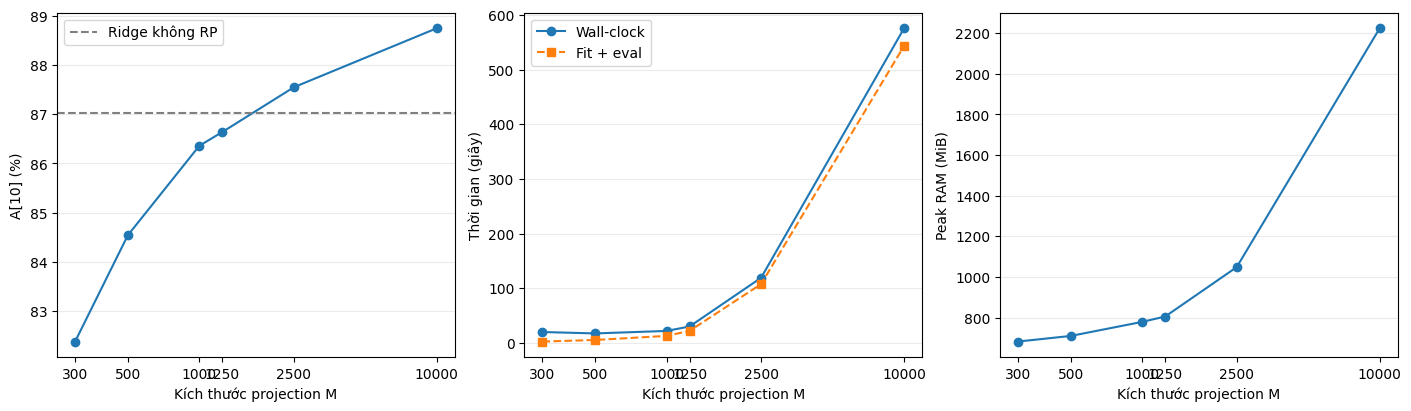

Kết quả đã lưu tại /content/drive/MyDrive/ranpac-runs/sweeps/m-sweep-s1993-m-sweep-01


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

summary = pd.DataFrame([
    json.loads((run_dir / 'benchmark.json').read_text(encoding='utf-8'))
    for run_dir in RUN_DIRS.values()
])
summary['delta_vs_ridge_pp'] = summary['a10_pct'] - RIDGE_BASELINE_A10_PCT
with atomic_output(SUMMARY_DIR / 'sweep_summary.csv') as temp:
    summary.to_csv(temp, index=False)
display(summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout='constrained')
axes[0].plot(summary['M'], summary['a10_pct'], 'o-')
axes[0].axhline(RIDGE_BASELINE_A10_PCT, linestyle='--', color='gray', label='Ridge không RP')
axes[0].set_ylabel('A[10] (%)')
axes[0].legend()
axes[1].plot(summary['M'], summary['wall_seconds'], 'o-', label='Wall-clock')
axes[1].plot(summary['M'], summary['fit_eval_seconds'], 's--', label='Fit + eval')
axes[1].set_ylabel('Thời gian (giây)')
axes[1].legend()
axes[2].plot(summary['M'], summary['peak_ram_mib'], 'o-')
axes[2].set_ylabel('Peak RAM (MiB)')
for axis in axes:
    axis.set_xlabel('Kích thước projection M')
    axis.set_xscale('log')
    axis.set_xticks(SWEEP_DIMS, labels=[str(dim) for dim in SWEEP_DIMS])
    axis.minorticks_off()
    axis.grid(axis='y', alpha=0.25)
with atomic_output(SUMMARY_DIR / 'sweep_metrics.png') as temp:
    fig.savefig(temp, format='png', dpi=150)
plt.show()
print(f'Kết quả đã lưu tại {SUMMARY_DIR}')